In [14]:
from pathlib import Path

PROJECT_DIR = Path("/content/avocado-ripening-classification")

folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "src",
    "models",
    "results/figures",
    "results/metrics",
    "sample_images",
    "report",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory created successfully.")
print(f"Location: {PROJECT_DIR}")

Project directory created successfully.
Location: /content/avocado-ripening-classification


In [15]:
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_dir():
        print(f"[DIR]  {path.relative_to(PROJECT_DIR)}")

[DIR]  data
[DIR]  data/processed
[DIR]  data/raw
[DIR]  models
[DIR]  notebooks
[DIR]  report
[DIR]  results
[DIR]  results/figures
[DIR]  results/metrics
[DIR]  sample_images
[DIR]  src


In [16]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
DRIVE_PROJECT_DIR = Path(
    "/content/drive/MyDrive/avocado-ripening-classification"
)

DRIVE_PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Google Drive project directory:")
print(DRIVE_PROJECT_DIR)

Google Drive project directory:
/content/drive/MyDrive/avocado-ripening-classification


In [18]:
archive_path = DRIVE_PROJECT_DIR / "Orange Dataset.zip"

if archive_path.exists():
    print("Dataset archive found!")
    print(f"File: {archive_path.name}")
    print(f"Size: {archive_path.stat().st_size / (1024 * 1024):.2f} MB")
else:
    raise FileNotFoundError(
        f"Dataset archive not found at: {archive_path}"
    )

Dataset archive found!
File: Orange Dataset.zip
Size: 138.18 MB


In [19]:
import zipfile

RAW_DATA_DIR = DRIVE_PROJECT_DIR / "data" / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(archive_path, "r") as zip_file:
    zip_file.extractall(RAW_DATA_DIR)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [20]:
for path in sorted(RAW_DATA_DIR.rglob("*")):
    if path.is_dir():
        print(f"[DIR]  {path.relative_to(RAW_DATA_DIR)}")

[DIR]  test
[DIR]  test/blackspot
[DIR]  test/canker
[DIR]  test/fresh
[DIR]  test/grenning
[DIR]  train
[DIR]  train/blackspot
[DIR]  train/canker
[DIR]  train/fresh
[DIR]  train/grenning


In [21]:
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

image_files = [
    path
    for path in RAW_DATA_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in IMAGE_EXTENSIONS
]

print(f"\nTotal image files: {len(image_files)}")

for image in image_files[:20]:
    print(image.relative_to(RAW_DATA_DIR))


Total image files: 1090
train/blackspot/b (1).jpg
train/blackspot/b (10).jpg
train/blackspot/b (100).jpg
train/blackspot/b (101).jpg
train/blackspot/b (102).jpg
train/blackspot/b (103).jpg
train/blackspot/b (104).jpg
train/blackspot/b (105).jpg
train/blackspot/b (106).jpg
train/blackspot/b (107).jpg
train/blackspot/b (108).jpg
train/blackspot/b (109).jpg
train/blackspot/b (11).jpg
train/blackspot/b (110).jpg
train/blackspot/b (111).jpg
train/blackspot/b (112).jpg
train/blackspot/b (113).jpg
train/blackspot/b (114).jpg
train/blackspot/b (115).jpg
train/blackspot/b (116).jpg


In [22]:
from collections import Counter
from pathlib import Path

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# Find all directories containing images
folder_counts = Counter()

for image_path in RAW_DATA_DIR.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
        relative_path = image_path.relative_to(RAW_DATA_DIR)
        folder_counts[str(relative_path.parent)] += 1

print("DATASET FOLDER SUMMARY")
print("=" * 50)

for folder, count in sorted(folder_counts.items()):
    print(f"{folder:<35} {count:>5} images")

print("\nTOTAL IMAGES:", sum(folder_counts.values()))

DATASET FOLDER SUMMARY
test/blackspot                         22 images
test/canker                            22 images
test/fresh                             33 images
test/grenning                          22 images
train/blackspot                       184 images
train/canker                          179 images
train/fresh                           281 images
train/grenning                        347 images

TOTAL IMAGES: 1090


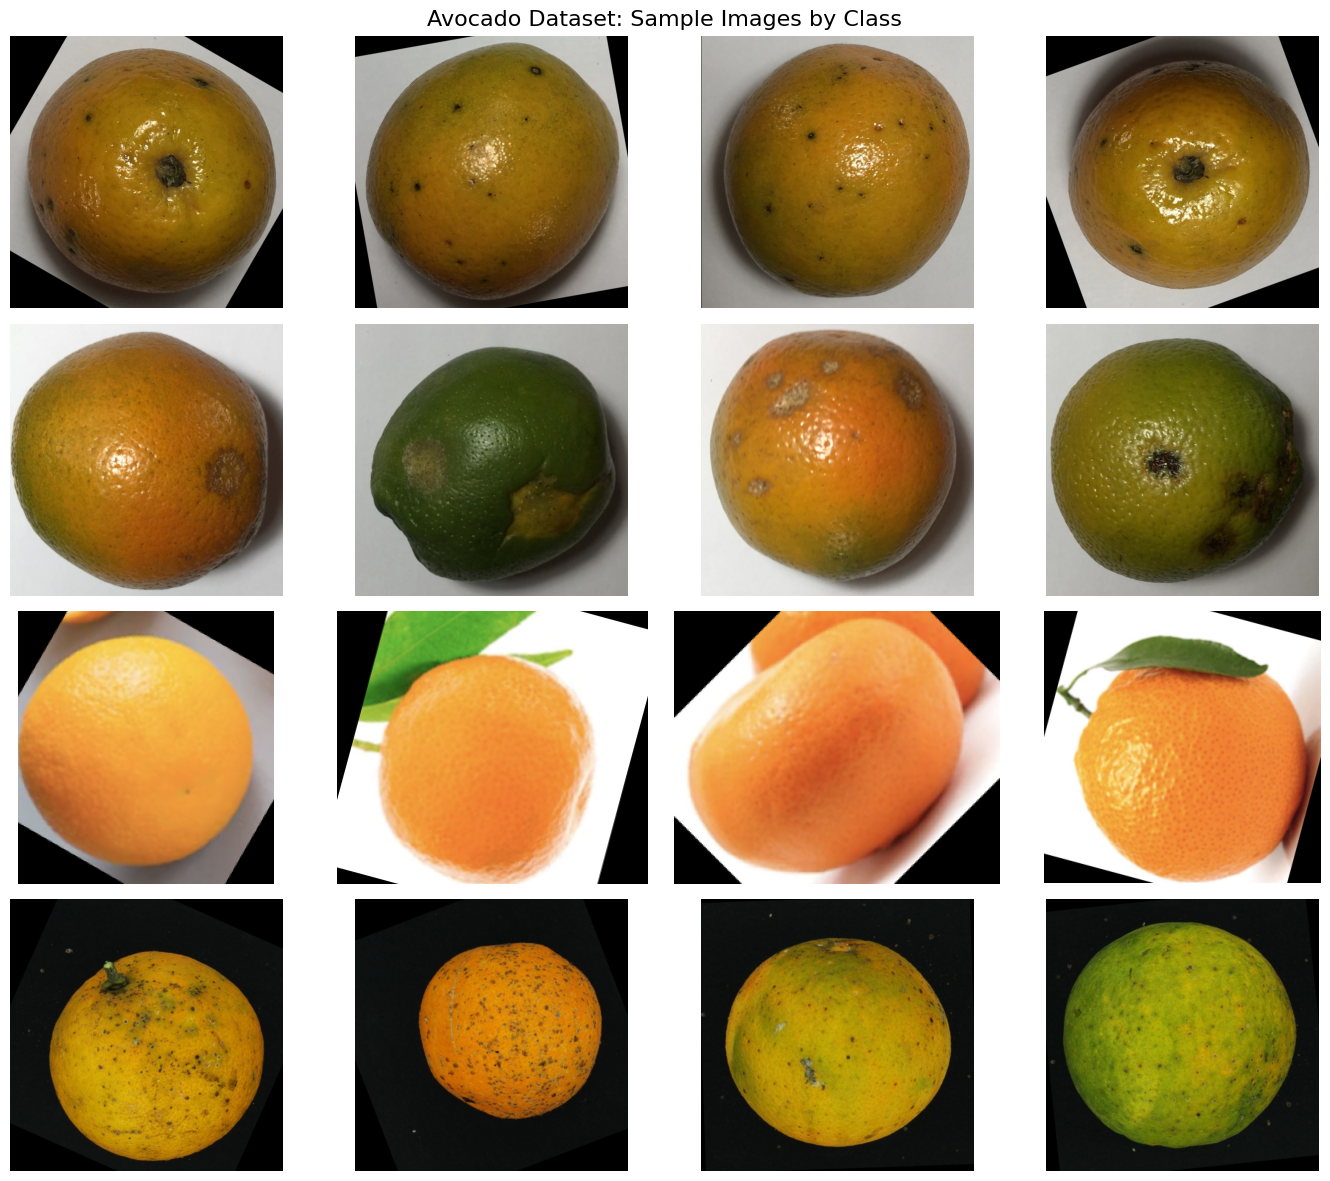

In [23]:
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

class_names = [
    "blackspot",
    "canker",
    "fresh",
    "grenning",
]

fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(14, 12)
)

for row, class_name in enumerate(class_names):
    class_dir = RAW_DATA_DIR / "train" / class_name

    image_paths = [
        path
        for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected_images = random.sample(
        image_paths,
        min(4, len(image_paths))
    )

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(selected_images):
            image = Image.open(
                selected_images[col]
            ).convert("RGB")

            ax.imshow(image)

            if col == 0:
                ax.set_ylabel(
                    class_name,
                    fontsize=12
                )

plt.suptitle(
    "Avocado Dataset: Sample Images by Class",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [24]:
from pathlib import Path
from collections import Counter
from PIL import Image
import pandas as pd

RAW_DATA_DIR = DRIVE_PROJECT_DIR / "data" / "raw"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

records = []
unreadable_images = []

for split in ["train", "test"]:
    split_dir = RAW_DATA_DIR / split

    if not split_dir.exists():
        print(f"Warning: {split} directory not found.")
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for image_path in sorted(class_dir.iterdir()):
            if (
                not image_path.is_file()
                or image_path.suffix.lower() not in IMAGE_EXTENSIONS
            ):
                continue

            try:
                with Image.open(image_path) as image:
                    width, height = image.size
                    image_format = image.format

                    image.verify()

                records.append({
                    "split": split,
                    "class_name": class_dir.name,
                    "filename": image_path.name,
                    "path": str(image_path),
                    "width": width,
                    "height": height,
                    "format": image_format,
                })

            except Exception as error:
                unreadable_images.append({
                    "path": str(image_path),
                    "error": str(error),
                })

df = pd.DataFrame(records)

print("DATASET SUMMARY")
print("=" * 50)
print(f"Readable images: {len(df)}")
print(f"Unreadable images: {len(unreadable_images)}")

print("\nIMAGE COUNTS BY SPLIT AND CLASS")

if not df.empty:
    print(
        df.groupby(["split", "class_name"])
        .size()
        .unstack(fill_value=0)
    )

    print("\nIMAGE DIMENSIONS")
    print(df[["width", "height"]].describe())

if unreadable_images:
    print("\nUNREADABLE IMAGE EXAMPLES")
    for item in unreadable_images[:10]:
        print(item["path"], "->", item["error"])

DATASET SUMMARY
Readable images: 1090
Unreadable images: 0

IMAGE COUNTS BY SPLIT AND CLASS
class_name  blackspot  canker  fresh  grenning
split                                         
test               22      22     33        22
train             184     179    281       347

IMAGE DIMENSIONS
             width       height
count  1090.000000  1090.000000
mean    669.022018   659.438532
std     211.551046   224.984294
min     144.000000   138.000000
25%     454.500000   400.000000
50%     800.000000   800.000000
75%     800.000000   800.000000
max     800.000000   800.000000


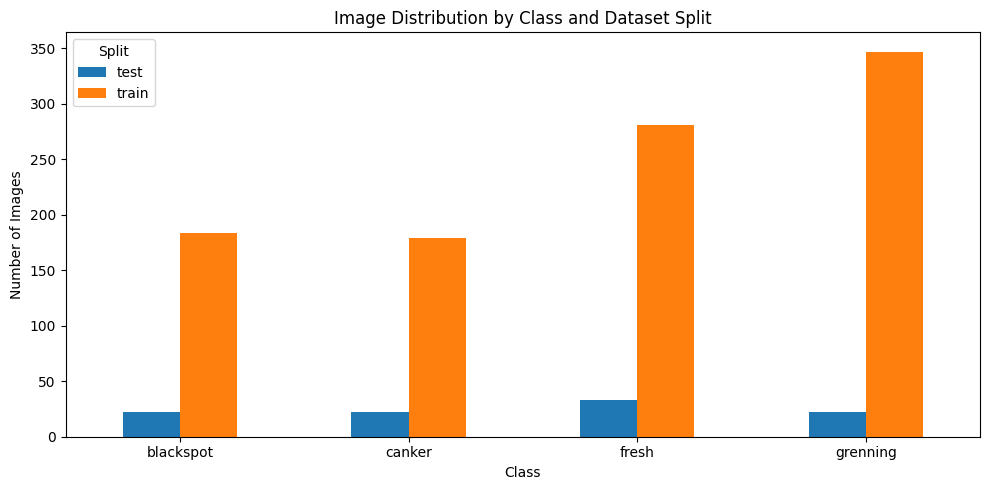

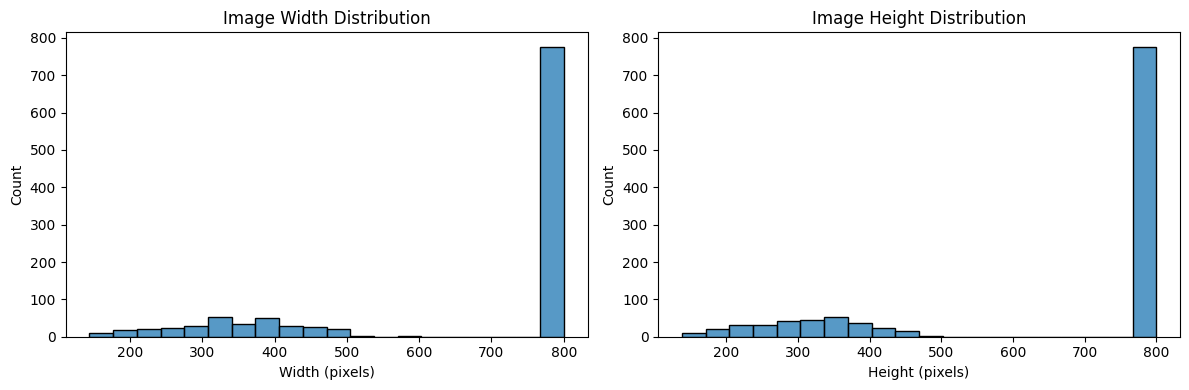

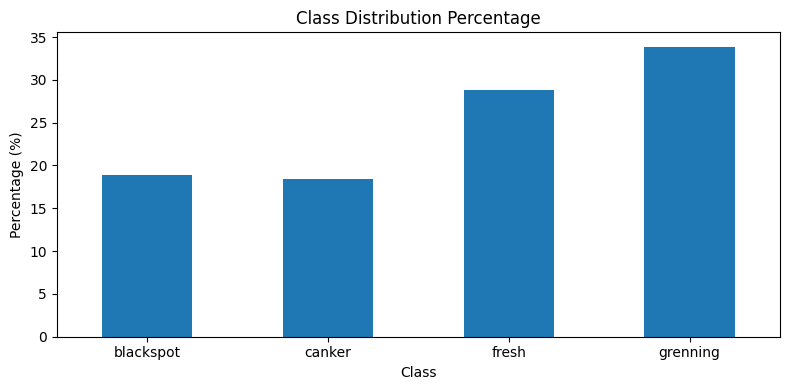

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep the class order consistent across the project.
class_names = [
    "blackspot",
    "canker",
    "fresh",
    "grenning",
]

# 1. Class distribution across training and test sets
class_counts = (
    df.groupby(["class_name", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(class_names)
)

ax = class_counts.plot(
    kind="bar",
    figsize=(10, 5),
)

ax.set_title("Image Distribution by Class and Dataset Split")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")
ax.legend(title="Split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 2. Image dimension distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=df,
    x="width",
    bins=20,
    ax=axes[0],
)

axes[0].set_title("Image Width Distribution")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(
    data=df,
    x="height",
    bins=20,
    ax=axes[1],
)

axes[1].set_title("Image Height Distribution")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()


# 3. Class imbalance percentages
class_percentages = (
    df["class_name"]
    .value_counts(normalize=True)
    .reindex(class_names)
    .mul(100)
)

plt.figure(figsize=(8, 4))

ax = class_percentages.plot(kind="bar")

ax.set_title("Class Distribution Percentage")
ax.set_xlabel("Class")
ax.set_ylabel("Percentage (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [26]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for image_path in df["path"]:
    digest = hashlib.sha256()

    with open(image_path, "rb") as image_file:
        for chunk in iter(
            lambda: image_file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    hash_groups[digest.hexdigest()].append(image_path)

duplicate_groups = [
    paths
    for paths in hash_groups.values()
    if len(paths) > 1
]

print("DUPLICATE IMAGE CHECK")
print("=" * 40)
print(f"Unique image hashes: {len(hash_groups)}")
print(f"Duplicate groups: {len(duplicate_groups)}")

for group in duplicate_groups[:10]:
    print("\nDuplicate files:")
    for path in group:
        print(" ", path)

DUPLICATE IMAGE CHECK
Unique image hashes: 1090
Duplicate groups: 0


In [27]:
from sklearn.model_selection import train_test_split
import pandas as pd

RANDOM_STATE = 42

# Separate the existing training and test records.
train_data = df[df["split"] == "train"].copy()
test_data = df[df["split"] == "test"].copy()

# Create a stratified validation split.
train_df, val_df = train_test_split(
    train_data,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=train_data["class_name"]
)

# Reset indices for easier processing.
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_data.reset_index(drop=True)

print("DATASET SPLIT SUMMARY")
print("=" * 45)

print(f"Training images   : {len(train_df)}")
print(f"Validation images : {len(val_df)}")
print(f"Testing images    : {len(test_df)}")

print("\nTRAINING CLASS DISTRIBUTION")
print(train_df["class_name"].value_counts().sort_index())

print("\nVALIDATION CLASS DISTRIBUTION")
print(val_df["class_name"].value_counts().sort_index())

print("\nTEST CLASS DISTRIBUTION")
print(test_df["class_name"].value_counts().sort_index())

DATASET SPLIT SUMMARY
Training images   : 842
Validation images : 149
Testing images    : 99

TRAINING CLASS DISTRIBUTION
class_name
blackspot    156
canker       152
fresh        239
grenning     295
Name: count, dtype: int64

VALIDATION CLASS DISTRIBUTION
class_name
blackspot    28
canker       27
fresh        42
grenning     52
Name: count, dtype: int64

TEST CLASS DISTRIBUTION
class_name
blackspot    22
canker       22
fresh        33
grenning     22
Name: count, dtype: int64


In [28]:
PROCESSED_DATA_DIR = (
    DRIVE_PROJECT_DIR / "data" / "processed"
)

PROCESSED_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

train_df.to_csv(
    PROCESSED_DATA_DIR / "train.csv",
    index=False
)

val_df.to_csv(
    PROCESSED_DATA_DIR / "validation.csv",
    index=False
)

test_df.to_csv(
    PROCESSED_DATA_DIR / "test.csv",
    index=False
)

print("Dataset splits saved successfully.")

Dataset splits saved successfully.


In [29]:
train_paths = set(train_df["path"])
val_paths = set(val_df["path"])
test_paths = set(test_df["path"])

print("DATA LEAKAGE CHECK")
print("=" * 45)

print(
    "Train / Validation overlap:",
    len(train_paths & val_paths)
)

print(
    "Train / Test overlap:",
    len(train_paths & test_paths)
)

print(
    "Validation / Test overlap:",
    len(val_paths & test_paths)
)

assert not (train_paths & val_paths)
assert not (train_paths & test_paths)
assert not (val_paths & test_paths)

assert (
    len(train_df) + len(val_df) + len(test_df)
    == len(df)
)

print("\nDataset split verification passed.")

DATA LEAKAGE CHECK
Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

Dataset split verification passed.


In [30]:
%pip install -q opencv-python-headless scikit-image scikit-learn joblib tqdm

In [31]:
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from skimage.feature import local_binary_pattern
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from tqdm.auto import tqdm

print("Classical ML libraries imported successfully.")
print("OpenCV version:", cv2.__version__)

Classical ML libraries imported successfully.
OpenCV version: 5.0.0


In [32]:
def extract_image_features(image_path):
    """Extract color and texture features from an image."""

    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image = cv2.resize(
        image,
        (128, 128),
        interpolation=cv2.INTER_AREA,
    )

    # Color features in HSV
    hsv_image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2HSV,
    )

    hsv_features = []

    for channel, bins, value_range in [
        (0, 24, [0, 180]),
        (1, 16, [0, 256]),
        (2, 16, [0, 256]),
    ]:
        histogram = cv2.calcHist(
            [hsv_image],
            [channel],
            None,
            [bins],
            value_range,
        )

        histogram = cv2.normalize(
            histogram,
            None,
            alpha=1.0,
            norm_type=cv2.NORM_L1,
        )

        hsv_features.extend(histogram.flatten())

    # Color features in CIELAB
    lab_image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2LAB,
    )

    lab_features = []

    for channel in range(3):
        histogram = cv2.calcHist(
            [lab_image],
            [channel],
            None,
            [16],
            [0, 256],
        )

        histogram = cv2.normalize(
            histogram,
            None,
            alpha=1.0,
            norm_type=cv2.NORM_L1,
        )

        lab_features.extend(histogram.flatten())

    # Texture features using Local Binary Patterns
    gray_image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY,
    )

    radius = 2
    points = 8 * radius

    lbp_image = local_binary_pattern(
        gray_image,
        P=points,
        R=radius,
        method="uniform",
    )

    lbp_histogram, _ = np.histogram(
        lbp_image.ravel(),
        bins=np.arange(0, points + 4),
        range=(0, points + 3),
    )

    lbp_histogram = lbp_histogram.astype(np.float32)
    lbp_histogram /= max(lbp_histogram.sum(), 1)

    # Combine all features into one vector.
    features = np.concatenate([
        np.asarray(hsv_features, dtype=np.float32),
        np.asarray(lab_features, dtype=np.float32),
        lbp_histogram,
    ])

    return features

In [33]:
sample_path = train_df.iloc[0]["path"]

sample_features = extract_image_features(sample_path)

print("Sample image:", Path(sample_path).name)
print("Feature vector shape:", sample_features.shape)
print("Feature vector dtype:", sample_features.dtype)
print("All features finite:", np.isfinite(sample_features).all())

Sample image: c (69).jpg
Feature vector shape: (123,)
Feature vector dtype: float32
All features finite: True


In [34]:
def build_feature_dataset(dataframe):
    """Convert a dataframe of image paths into feature arrays."""

    feature_rows = []
    labels = []

    for image_path, label in tqdm(
        zip(dataframe["path"], dataframe["class_name"]),
        total=len(dataframe),
        desc="Extracting features",
    ):
        features = extract_image_features(image_path)

        feature_rows.append(features)
        labels.append(label)

    return (
        np.asarray(feature_rows, dtype=np.float32),
        np.asarray(labels),
    )


X_train, y_train = build_feature_dataset(train_df)

X_val, y_val = build_feature_dataset(val_df)

X_test, y_test = build_feature_dataset(test_df)

print("\nFeature extraction completed.")

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

Extracting features:   0%|          | 0/842 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/149 [00:00<?, ?it/s]

Extracting features:   0%|          | 0/99 [00:00<?, ?it/s]


Feature extraction completed.
Training features: (842, 123)
Validation features: (149, 123)
Test features: (99, 123)


In [35]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    (
        "classifier",
        SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

svm_model.fit(X_train, y_train)

print("SVM training completed successfully.")

SVM training completed successfully.


In [36]:
y_val_pred = svm_model.predict(X_val)

val_accuracy = accuracy_score(
    y_val,
    y_val_pred,
)

val_macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro",
)

print("SVM VALIDATION RESULTS")
print("=" * 45)

print(f"Accuracy:   {val_accuracy:.4f}")
print(f"Macro F1:   {val_macro_f1:.4f}")

print("\nClassification report:\n")

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=class_names,
        zero_division=0,
    )
)

SVM VALIDATION RESULTS
Accuracy:   0.9866
Macro F1:   0.9831

Classification report:

              precision    recall  f1-score   support

   blackspot       0.97      1.00      0.98        28
      canker       1.00      0.93      0.96        27
       fresh       0.98      1.00      0.99        42
    grenning       1.00      1.00      1.00        52

    accuracy                           0.99       149
   macro avg       0.99      0.98      0.98       149
weighted avg       0.99      0.99      0.99       149



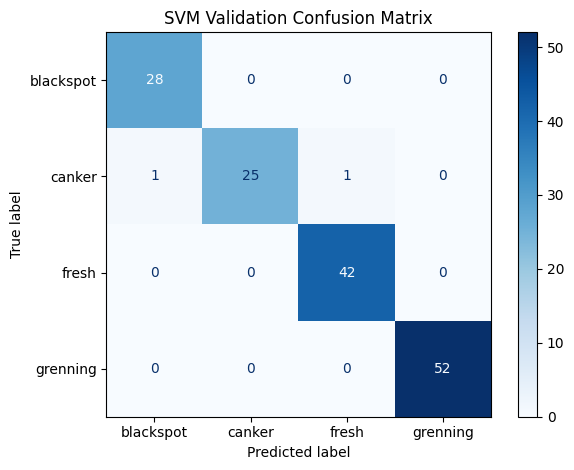

In [37]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=class_names,
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
)

display.plot(
    cmap="Blues",
    values_format="d",
)

plt.title("SVM Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [38]:
MODEL_DIR = DRIVE_PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

svm_model_path = MODEL_DIR / "classical_svm.joblib"

joblib.dump(
    svm_model,
    svm_model_path,
)

print("SVM model saved to:")
print(svm_model_path)

SVM model saved to:
/content/drive/MyDrive/avocado-ripening-classification/models/classical_svm.joblib


In [39]:
import torch
import torchvision
import time
import copy
import numpy as np

from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Training device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable. Training will use the CPU.")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
Training device: cuda
GPU: Tesla T4


In [40]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.10,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

print("Image transformations configured.")

Image transformations configured.


In [41]:
class_names = [
    "blackspot",
    "canker",
    "fresh",
    "grenning",
]

class_to_idx = {
    name: index
    for index, name in enumerate(class_names)
}

print("Class mapping:")
print(class_to_idx)

Class mapping:
{'blackspot': 0, 'canker': 1, 'fresh': 2, 'grenning': 3}


In [42]:
class OrangeImageDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image_path = row["path"]
        label = class_to_idx[row["class_name"]]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [43]:
train_dataset = OrangeImageDataset(
    train_df,
    transform=train_transforms,
)

val_dataset = OrangeImageDataset(
    val_df,
    transform=eval_transforms,
)

test_dataset = OrangeImageDataset(
    test_df,
    transform=eval_transforms,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 27
Validation batches: 5
Test batches: 4


In [44]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in first batch:", labels[:10].tolist())

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in first batch: [3, 0, 2, 0, 0, 1, 3, 2, 2, 1]


In [45]:
weights = models.MobileNet_V2_Weights.DEFAULT

mobilenet_model = models.mobilenet_v2(
    weights=weights
)

# Freeze the pretrained feature extractor initially.
for parameter in mobilenet_model.features.parameters():
    parameter.requires_grad = False

# Replace the original classification layer.
in_features = mobilenet_model.classifier[1].in_features

mobilenet_model.classifier[1] = nn.Linear(
    in_features,
    len(class_names),
)

mobilenet_model = mobilenet_model.to(device)

print("MobileNetV2 initialized.")
print("Number of output classes:", len(class_names))

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 95.6MB/s]


MobileNetV2 initialized.
Number of output classes: 4


In [46]:
from sklearn.utils.class_weight import compute_class_weight

training_labels = train_df["class_name"].to_numpy()

weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.array(class_names),
    y=training_labels,
)

class_weights = torch.tensor(
    weights_array,
    dtype=torch.float32,
    device=device,
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    mobilenet_model.classifier.parameters(),
    lr=0.001,
)

print("Class weights:")
for name, weight in zip(class_names, weights_array):
    print(f"{name}: {weight:.3f}")

Class weights:
blackspot: 1.349
canker: 1.385
fresh: 0.881
grenning: 0.714


In [47]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None

    model.train() if training else model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    average_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(
        all_labels,
        all_predictions,
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0,
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
    }

In [48]:
EPOCHS = 8

best_val_f1 = -1.0
best_epoch = 0
history = []

MODEL_DIR = DRIVE_PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_model_path = MODEL_DIR / "mobilenet_v2_best.pth"

start_time = time.time()

for epoch in range(EPOCHS):
    train_metrics = run_epoch(
        mobilenet_model,
        train_loader,
        criterion,
        optimizer,
    )

    val_metrics = run_epoch(
        mobilenet_model,
        val_loader,
        criterion,
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train accuracy: {train_metrics['accuracy']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val macro F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch + 1

        torch.save(
            {
                "model_state_dict": mobilenet_model.state_dict(),
                "class_names": class_names,
                "epoch": best_epoch,
                "val_macro_f1": best_val_f1,
            },
            best_model_path,
        )

elapsed_time = time.time() - start_time

history_df = pd.DataFrame(history)

print("\nTraining completed.")
print(f"Best epoch: {best_epoch}")
print(f"Best validation macro F1: {best_val_f1:.4f}")
print(f"Training time: {elapsed_time:.1f} seconds")
print(f"Best model saved to: {best_model_path}")

Epoch 1/8 | Train loss: 0.8770 | Train accuracy: 0.8100 | Val loss: 0.5596 | Val accuracy: 0.9396 | Val macro F1: 0.9169
Epoch 2/8 | Train loss: 0.3945 | Train accuracy: 0.9632 | Val loss: 0.3346 | Val accuracy: 0.9530 | Val macro F1: 0.9363
Epoch 3/8 | Train loss: 0.2640 | Train accuracy: 0.9620 | Val loss: 0.2433 | Val accuracy: 0.9732 | Val macro F1: 0.9635
Epoch 4/8 | Train loss: 0.2004 | Train accuracy: 0.9798 | Val loss: 0.1985 | Val accuracy: 0.9866 | Val macro F1: 0.9818
Epoch 5/8 | Train loss: 0.1707 | Train accuracy: 0.9762 | Val loss: 0.1711 | Val accuracy: 0.9866 | Val macro F1: 0.9818
Epoch 6/8 | Train loss: 0.1454 | Train accuracy: 0.9798 | Val loss: 0.1498 | Val accuracy: 1.0000 | Val macro F1: 1.0000
Epoch 7/8 | Train loss: 0.1314 | Train accuracy: 0.9798 | Val loss: 0.1305 | Val accuracy: 0.9933 | Val macro F1: 0.9909
Epoch 8/8 | Train loss: 0.1174 | Train accuracy: 0.9857 | Val loss: 0.1213 | Val accuracy: 0.9933 | Val macro F1: 0.9909

Training completed.
Best epoch:

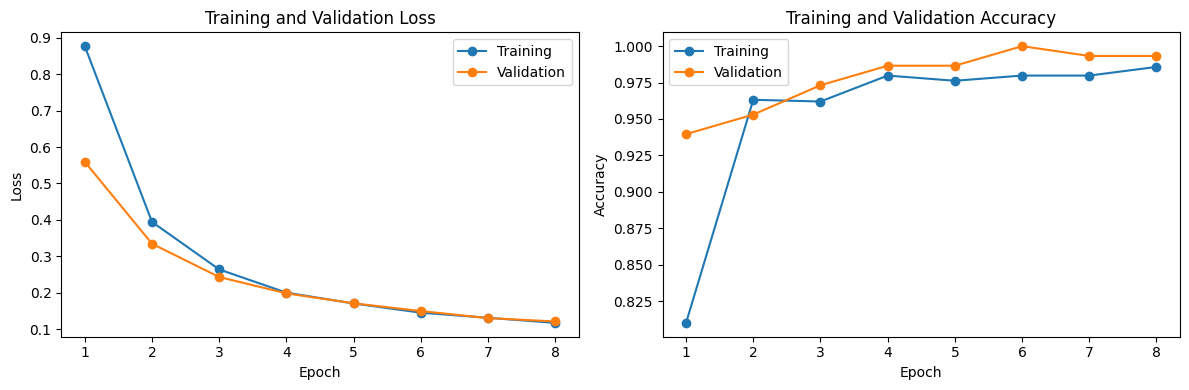

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training",
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation",
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training",
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation",
)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [50]:
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True,
)

mobilenet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

mobilenet_model.eval()

print("Loaded best MobileNetV2 checkpoint.")
print("Selected epoch:", checkpoint["epoch"])
print("Validation macro F1:", checkpoint["val_macro_f1"])

Loaded best MobileNetV2 checkpoint.
Selected epoch: 6
Validation macro F1: 1.0


In [51]:
val_metrics = run_epoch(
    mobilenet_model,
    val_loader,
    criterion,
)

print("MOBILENETV2 VALIDATION RESULTS")
print("=" * 45)
print(f"Accuracy: {val_metrics['accuracy']:.4f}")
print(f"Macro F1: {val_metrics['macro_f1']:.4f}")

MOBILENETV2 VALIDATION RESULTS
Accuracy: 1.0000
Macro F1: 1.0000


In [52]:
def get_predictions(model, loader):
    model.eval()

    true_labels = []
    predicted_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            true_labels.extend(labels.numpy())
            predicted_labels.extend(predictions.cpu().numpy())

    return (
        np.asarray(true_labels),
        np.asarray(predicted_labels),
    )


y_val_dl, y_val_dl_pred = get_predictions(
    mobilenet_model,
    val_loader,
)

print(
    classification_report(
        y_val_dl,
        y_val_dl_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

   blackspot       1.00      1.00      1.00        28
      canker       1.00      1.00      1.00        27
       fresh       1.00      1.00      1.00        42
    grenning       1.00      1.00      1.00        52

    accuracy                           1.00       149
   macro avg       1.00      1.00      1.00       149
weighted avg       1.00      1.00      1.00       149



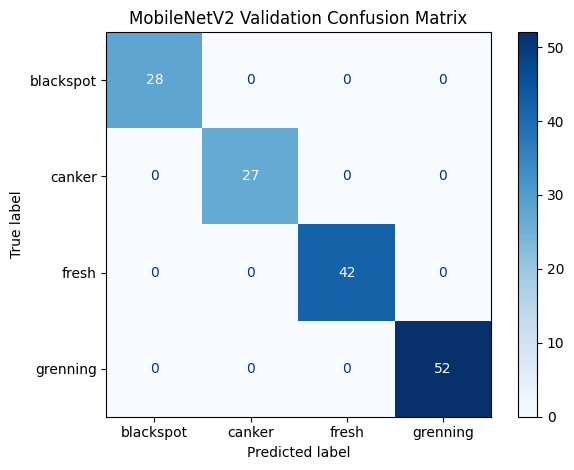

In [53]:
cm_dl = confusion_matrix(
    y_val_dl,
    y_val_dl_pred,
    labels=list(range(len(class_names))),
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_dl,
    display_labels=class_names,
)

display.plot(
    cmap="Blues",
    values_format="d",
)

plt.title("MobileNetV2 Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [54]:
# Load the best saved checkpoint.
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True,
)

mobilenet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

mobilenet_model.eval()

# Predict the test labels.
y_test_dl, y_test_dl_pred = get_predictions(
    mobilenet_model,
    test_loader,
)

# Calculate final test metrics.
dl_test_accuracy = accuracy_score(
    y_test_dl,
    y_test_dl_pred,
)

dl_test_macro_f1 = f1_score(
    y_test_dl,
    y_test_dl_pred,
    average="macro",
)

print("MOBILENETV2 TEST RESULTS")
print("=" * 45)
print(f"Accuracy: {dl_test_accuracy:.4f}")
print(f"Macro F1: {dl_test_macro_f1:.4f}")

print("\nClassification report:\n")

print(
    classification_report(
        y_test_dl,
        y_test_dl_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    )
)

MOBILENETV2 TEST RESULTS
Accuracy: 0.9495
Macro F1: 0.9445

Classification report:

              precision    recall  f1-score   support

   blackspot       0.91      0.91      0.91        22
      canker       0.90      0.86      0.88        22
       fresh       0.97      1.00      0.99        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.95        99
   macro avg       0.95      0.94      0.94        99
weighted avg       0.95      0.95      0.95        99



In [55]:
y_test_svm_pred = svm_model.predict(X_test)

svm_test_accuracy = accuracy_score(
    y_test,
    y_test_svm_pred,
)

svm_test_macro_f1 = f1_score(
    y_test,
    y_test_svm_pred,
    average="macro",
)

print("SVM TEST RESULTS")
print("=" * 45)
print(f"Accuracy: {svm_test_accuracy:.4f}")
print(f"Macro F1: {svm_test_macro_f1:.4f}")

print("\nClassification report:\n")

print(
    classification_report(
        y_test,
        y_test_svm_pred,
        labels=class_names,
        zero_division=0,
    )
)

SVM TEST RESULTS
Accuracy: 0.9697
Macro F1: 0.9659

Classification report:

              precision    recall  f1-score   support

   blackspot       0.91      0.95      0.93        22
      canker       0.95      0.91      0.93        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99



In [56]:
comparison_df = pd.DataFrame([
    {
        "Model": "Classical SVM",
        "Test Accuracy": svm_test_accuracy,
        "Test Macro F1": svm_test_macro_f1,
    },
    {
        "Model": "MobileNetV2",
        "Test Accuracy": dl_test_accuracy,
        "Test Macro F1": dl_test_macro_f1,
    },
])

print(comparison_df.to_string(index=False))

        Model  Test Accuracy  Test Macro F1
Classical SVM       0.969697       0.965891
  MobileNetV2       0.949495       0.944472


In [57]:
from pathlib import Path
import pandas as pd

RESULTS_DIR = DRIVE_PROJECT_DIR / "results" / "metrics"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

final_results = pd.DataFrame([
    {
        "Model": "Classical SVM",
        "Test Accuracy": svm_test_accuracy,
        "Test Macro F1": svm_test_macro_f1,
    },
    {
        "Model": "MobileNetV2",
        "Test Accuracy": dl_test_accuracy,
        "Test Macro F1": dl_test_macro_f1,
    },
])

results_path = RESULTS_DIR / "model_comparison.csv"

final_results.to_csv(results_path, index=False)

print(final_results.to_string(index=False))
print(f"\nResults saved to: {results_path}")

        Model  Test Accuracy  Test Macro F1
Classical SVM       0.969697       0.965891
  MobileNetV2       0.949495       0.944472

Results saved to: /content/drive/MyDrive/avocado-ripening-classification/results/metrics/model_comparison.csv


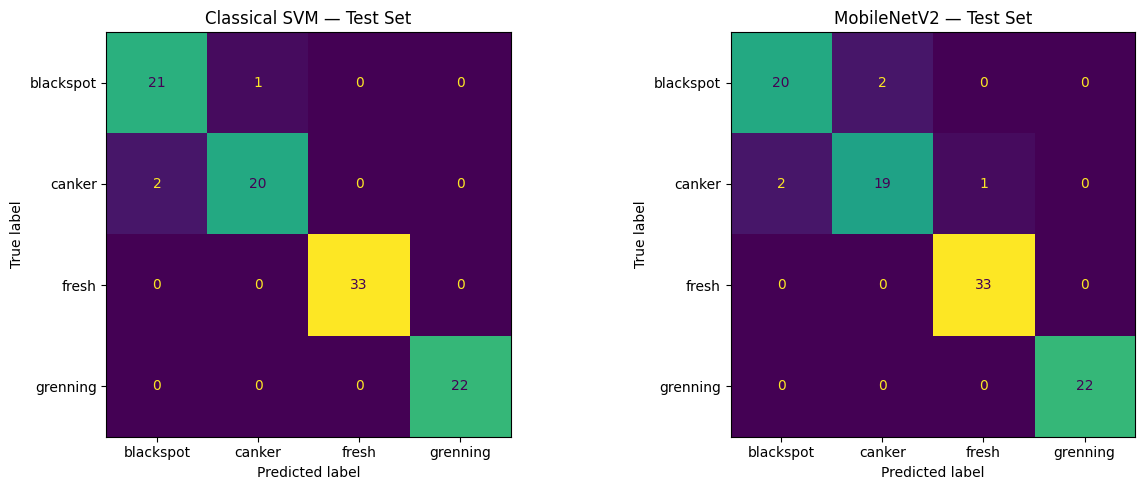

In [58]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

svm_cm = confusion_matrix(
    y_test,
    y_test_svm_pred,
    labels=class_names,
)

dl_cm = confusion_matrix(
    y_test_dl,
    y_test_dl_pred,
    labels=list(range(len(class_names))),
)

ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=class_names,
).plot(ax=axes[0], values_format="d", colorbar=False)

axes[0].set_title("Classical SVM — Test Set")

ConfusionMatrixDisplay(
    confusion_matrix=dl_cm,
    display_labels=class_names,
).plot(ax=axes[1], values_format="d", colorbar=False)

axes[1].set_title("MobileNetV2 — Test Set")

plt.tight_layout()

figure_path = DRIVE_PROJECT_DIR / "results" / "figures"
figure_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_path / "test_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [59]:
import joblib
import torch
import matplotlib.pyplot as plt
import numpy as np

from PIL import Image
from pathlib import Path

# Load the saved SVM pipeline.
svm_model = joblib.load(
    DRIVE_PROJECT_DIR / "models" / "classical_svm.joblib"
)

# Load the best MobileNetV2 checkpoint.
checkpoint = torch.load(
    DRIVE_PROJECT_DIR / "models" / "mobilenet_v2_best.pth",
    map_location=device,
    weights_only=True,
)

mobilenet_model.load_state_dict(
    checkpoint["model_state_dict"]
)
mobilenet_model.eval()


def predict_image(image_path):
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # Classical SVM prediction.
    features = extract_image_features(image_path).reshape(1, -1)
    svm_prediction = svm_model.predict(features)[0]

    # MobileNetV2 prediction.
    with Image.open(image_path) as image:
        display_image = image.convert("RGB")
        input_tensor = eval_transforms(display_image).unsqueeze(0)

    with torch.no_grad():
        output = mobilenet_model(
            input_tensor.to(device)
        )
        probabilities = torch.softmax(output, dim=1)[0]
        predicted_index = int(probabilities.argmax().item())

    dl_prediction = class_names[predicted_index]
    confidence = float(probabilities[predicted_index].item())

    # Display both predictions.
    plt.figure(figsize=(7, 5))
    plt.imshow(display_image)
    plt.axis("off")
    plt.title(
        f"SVM: {svm_prediction}\n"
        f"MobileNetV2: {dl_prediction} "
        f"({confidence:.1%} model confidence)"
    )
    plt.tight_layout()
    plt.show()

    print("SVM prediction:", svm_prediction)
    print("MobileNetV2 prediction:", dl_prediction)
    print(f"MobileNetV2 confidence: {confidence:.2%}")

    return {
        "image": str(image_path),
        "svm_prediction": svm_prediction,
        "mobilenet_prediction": dl_prediction,
        "mobilenet_confidence": confidence,
    }

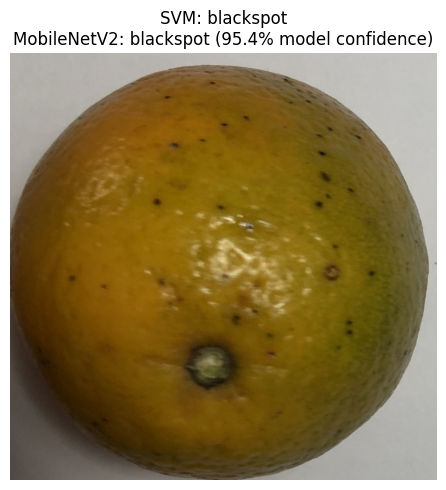

SVM prediction: blackspot
MobileNetV2 prediction: blackspot
MobileNetV2 confidence: 95.39%


In [60]:
sample_image_path = test_df.iloc[0]["path"]

prediction_result = predict_image(sample_image_path)